# Model performance and sensitivity

Native reconstruction comparisons for Figure 5 and Supplementary Figures 4–6. Each setup uses a complete native ensemble and the same observed national mortality series.

[Original analysis notebook](https://github.com/ClimSocAna/sari-weather-mortality/blob/4402a80d3e490ad7964a3be12597043761bebda1/notebooks/04_model_performance_sensitivity.ipynb).

The primary hybrid uses 50 members. Comparison ensembles use all of their available members.

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

daily_index = notebook_utils.daily_index
ensemble = notebook_utils.ensemble
national_daily = notebook_utils.national_daily
ANALYSIS_PERIOD = notebook_utils.ANALYSIS_PERIOD
DEVICE = notebook_utils.DEVICE
checkpoint_paths = notebook_utils.checkpoint_paths

from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor

## Load models for inspection

Run the next cell to load member `000` for each setup into memory. Inspect `model` for the hybrid predictor or `models[setup]` for another predictor. Set `inspection_member` to another available member index to inspect its weights. The analysis cells evaluate all available members in a separate inference workspace.

In [ ]:
inspection_member = 0
set_up = {
    "sari_COVID": "exclude_temperature",
    "t_only": "temperature_only",
    "t_sari": "no_covid",
    "baseline_static": "baseline_static",
    "baseline_adaptive": "default",
    "tas_only": "tas_only",
    "tas_wetbulb": "tas_wet_bulb",
    "baseline_trimmed_mean": "baseline_trimmed_mean",
    "baseline_ewma_double_side": "baseline_double_sided",
    "corr_off": "no_mean_alignment",
    "corr_on": "default",
    "weather_dew_point": "no_disease",
}
setups = dict.fromkeys(set_up.values())
checkpoints = {setup: checkpoint_paths(setup) for setup in setups}
models = {
    setup: restore_predictor(load_checkpoint(paths[inspection_member]), device="cpu").eval()
    for setup, paths in checkpoints.items()
}
model = models["default"]
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Evaluate the native experiment registry

In [ ]:
summaries = dict.fromkeys(setups, national_daily)

estimates_by_setup = {}
for setup, summarize_member in summaries.items():
    paths = checkpoints[setup]
    inputs = load_run_config(paths[0].parents[1] / "config.yaml").data_config
    inference_model = InferenceModel.from_checkpoint(
        paths[0], data_config=inputs, period=ANALYSIS_PERIOD, device=DEVICE,
    )
    estimates_by_setup[setup] = ensemble(inference_model, paths, summarize_member)
    del inference_model

predictions = estimates_by_setup
dates = daily_index()
observed = predictions["default"]["Observed"].numpy()
if any(not np.array_equal(observed, values["Observed"].numpy())
       for values in predictions.values()):
    raise ValueError("All setups must use the same observed labels.")

val = predictions["default"]["Observed"]
tr = {label: predictions[setup]["Predicted"] for label, setup in set_up.items()}
df = pd.DataFrame({"date": dates})
df["year"] = df["date"].dt.year
df["week"] = df["date"].dt.isocalendar().week.astype(int)

## Period-specific reconstruction metrics

RMSE and R² are evaluated for epidemiologically and chronologically defined windows. The influenza season spans ISO weeks 40-20, while the summer period spans weeks 15-38. Validation covers 2023-2024 and the held-out test period is 2025.

In [ ]:
import warnings
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore', category=DeprecationWarning)

mask_by_period = {
    'Overall': np.ones(len(df), dtype=bool),
    'Influenza Season': ((df['week'] >= 40) | (df['week'] <= 20)).to_numpy(dtype=bool, copy=True),
    'Summer Period': ((df['week'] >= 15) & (df['week'] <= 38)).to_numpy(dtype=bool, copy=True),
    'Pre-pandemic': (df['year'] <= 2019).to_numpy(dtype=bool, copy=True),
    'Pandemic': ((df['year'] >= 2020) & (df['year'] <= 2022)).to_numpy(dtype=bool, copy=True),
    'Validation': ((df['year'] >= 2023) & (df['year'] <= 2024)).to_numpy(dtype=bool, copy=True),
    'Test': ((df['year'] >= 2025)).to_numpy(dtype=bool, copy=True),
}

def rmse(x):
    return (x.pow(2).mean().sqrt()).item()

rmse_dict = {}
r2_dict = {}
time_period = list(mask_by_period.keys())

for k, pred in tr.items():
    print(f'{k:25s}', end=' ')
    diff = pred - val
    rmse_vals = [rmse(diff[m]) for m in mask_by_period.values()]
    print(''.join(f'{v:10.2f}' for v in rmse_vals))

    r2_vals = [r2_score(val[m], pred[m]) for m in mask_by_period.values()]
    print(f'{" ":26s}' + ''.join(f'{v:10.4f}' for v in r2_vals))

    rmse_dict[k] = rmse_vals
    r2_dict[k] = r2_vals

sari_COVID                    123.95    111.68    135.92    125.17    130.18    115.13    115.01
                              0.8523    0.8749    0.5194    0.8042    0.8574    0.8187    0.8424
t_only                        177.48    211.34    103.93    158.46    199.38    209.94    121.56
                              0.6971    0.5522    0.7190    0.6861    0.6655    0.3972    0.8239
t_sari                         84.38     89.36     74.87     71.10     97.82     89.75     93.18
                              0.9315    0.9199    0.8542    0.9368    0.9195    0.8898    0.8965
baseline_static               125.71    130.55    116.12     77.35    108.34    192.55    192.01
                              0.8480    0.8291    0.6493    0.9252    0.9012    0.4929    0.5606
baseline_adaptive              80.82     84.23     73.93     71.01     92.54     82.75     87.03
                              0.9372    0.9289    0.8578    0.9370    0.9279    0.9063    0.9097
tas_only                      

In [ ]:
tr_keys = list(tr.keys())
rmse_tensor = torch.tensor([rmse_dict[k] for k in tr_keys])
r2_tensor = torch.tensor([r2_dict[k] for k in tr_keys])

## Supplementary Figure 4: Input-component sensitivity

This panel compares respiratory-infection-only, both weather-only configurations, weather plus total SARI, and the full hybrid configuration. These results provide the model-input comparison summarized compactly in Manuscript Figure 5 and the detailed period comparison in the supplement.

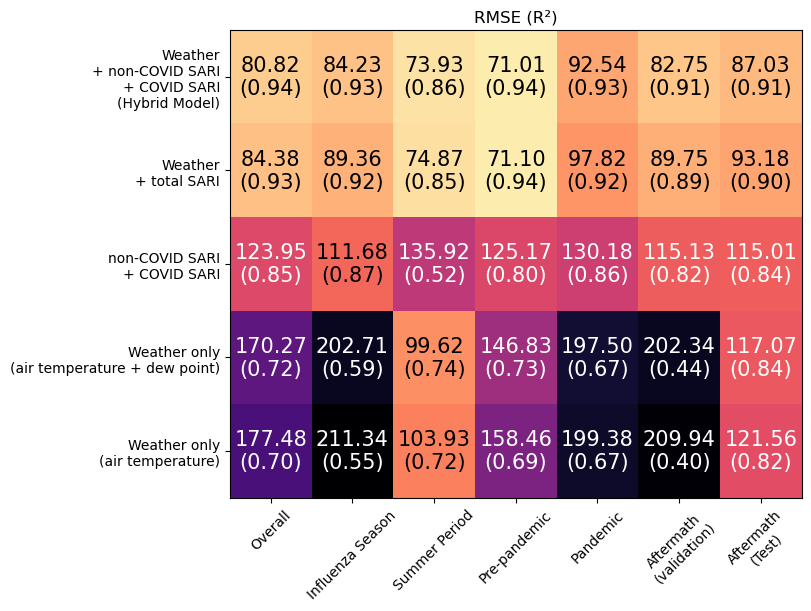

In [ ]:
from matplotlib.colors import Normalize

norm = Normalize(vmin=rmse_tensor.min(), vmax=rmse_tensor.max())
windows = ['Overall', 'Influenza Season', 'Summer Period', 'Pre-pandemic', 'Pandemic', 'Aftermath\n(validation)', 'Aftermath\n(Test)']

def heat(ax, data, data_aux, row_labels, col_labels, title, cmap='magma', reverse=False, norm=None):
    cmap_obj = plt.get_cmap(cmap).reversed() if reverse else plt.get_cmap(cmap)
    im = ax.imshow(data, aspect='auto', cmap=cmap_obj, norm=norm)
    ax.set_xticks(np.arange(len(col_labels)))
    ax.set_xticklabels(col_labels, rotation=45)
    ax.set_yticks(np.arange(len(row_labels)))
    ax.set_yticklabels(row_labels)
    ax.set_title(title)

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            v_aux = data_aux[i, j]
            r, g, b, _ = cmap_obj(norm(v)) if norm is not None else cmap_obj(v)
            luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
            color = 'black' if luminance > 0.5 else 'white'
            ax.text(j, i, f'{v:.2f}\n({v_aux:.2f})', ha='center', va='center', color=color, fontsize=15)
    return im

def plot_model_heatmap(model_labels, idx, title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True):
    rmse_arr = rmse_tensor[idx].numpy()
    r2_arr = r2_tensor[idx].numpy()
    order = np.argsort(rmse_arr.mean(axis=1))
    rmse_arr, r2_arr = rmse_arr[order], r2_arr[order]
    labels = [model_labels[i] for i in order]

    fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=True)
    heat(ax, rmse_arr, r2_arr, labels, windows, title, cmap=cmap, reverse=reverse, norm=norm)
    return fig, ax

models_input = {
    "sari_COVID": "non-COVID SARI\n+ COVID SARI",
    "t_only": "Weather only\n(air temperature)",
    "weather_dew_point": "Weather only\n(air temperature + dew point)",
    "t_sari": "Weather\n+ total SARI",
    "baseline_adaptive": "Weather\n+ non-COVID SARI\n+ COVID SARI\n(Hybrid Model)",
}
plot_model_heatmap(list(models_input.values()), [tr_keys.index(key) for key in models_input],
                   title="RMSE (R²)", figsize=(8, 6), cmap="magma", reverse=True)
# plt.savefig('model_comparison_input.png', dpi=300, bbox_inches='tight')
plt.show()

## Supplementary Figure 6: Baseline-method sensitivity

Static, median-EWMA, trimmed-mean, and double-sided median-EWMA baselines are compared using the same reconstruction metrics. This analysis tests whether the hybrid model's performance depends on one particular background-mortality definition.

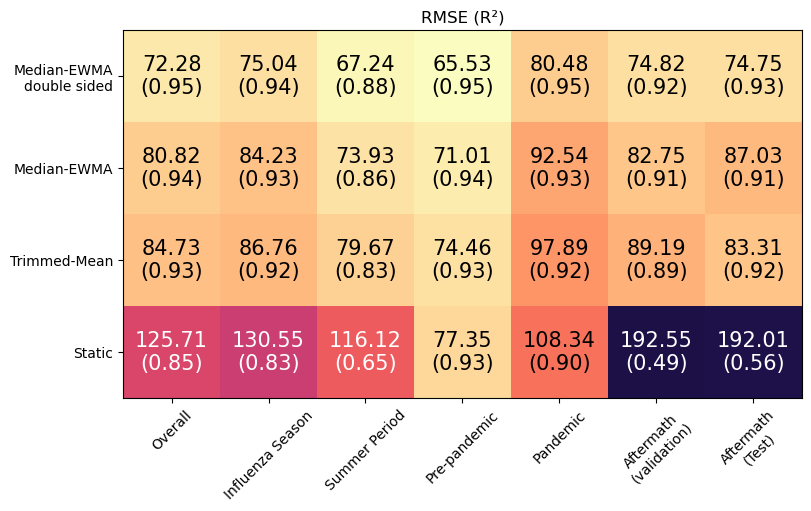

In [ ]:
models_baseline = ['Static', 'Median-EWMA', 'Trimmed-Mean', 'Median-EWMA\ndouble sided']
plot_model_heatmap(models_baseline, [3, 4, 7, 8], title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True)
# plt.savefig('model_comparison_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

## Supplementary Figure 5: Humidity-indicator sensitivity

The final comparison evaluates air temperature plus dew point, air temperature alone, and air temperature plus wet-bulb temperature. It complements the fitted response curves in Manuscript Figure 2 with reconstruction-based evidence.

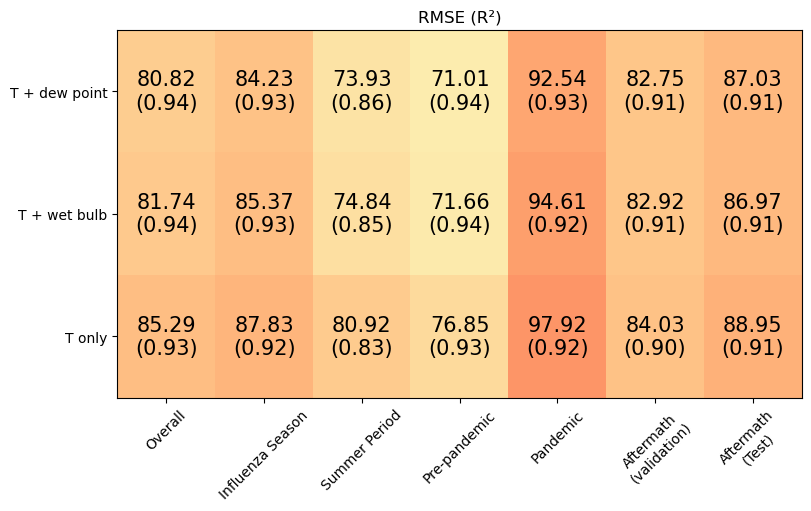

In [ ]:
models_weather = ['T + dew point', 'T only', 'T + wet bulb']
plot_model_heatmap(models_weather, [4, 5, 6], title='RMSE (R²)', figsize=(8, 5), cmap='magma', reverse=True)
# plt.savefig('model_comparison_humidity.png', dpi=300, bbox_inches='tight')
plt.show()

## Manuscript Figure 5: Reconstruction RMSE by input configuration

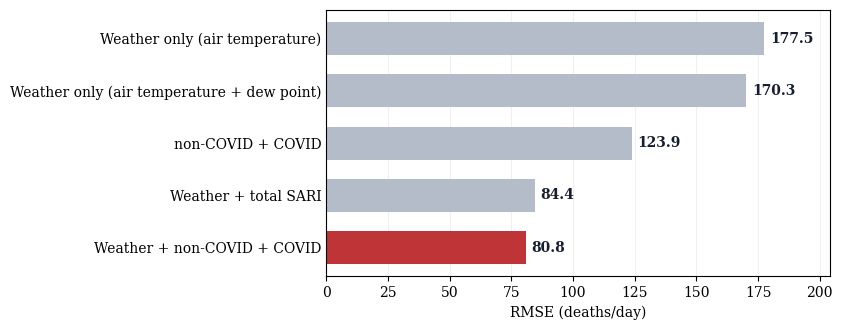

In [ ]:
labels = {
    "t_only": "Weather only (air temperature)",
    "weather_dew_point": "Weather only (air temperature + dew point)",
    "sari_COVID": "non-COVID + COVID",
    "t_sari": "Weather + total SARI",
    "baseline_adaptive": "Weather + non-COVID + COVID",
}
ordered = sorted(labels, key=lambda key: rmse_dict[key][0], reverse=True)
values = [rmse_dict[key][0] for key in ordered]
with plt.rc_context({"font.family": "DejaVu Serif", "axes.axisbelow": True}):
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    bars = ax.barh([labels[key] for key in ordered], values, height=0.63,
                   color=["#bf3436" if key == "baseline_adaptive" else "#b3bcc8" for key in ordered])
    ax.invert_yaxis()
    ax.set(xlabel="RMSE (deaths/day)", xlim=(0, max(200, max(values) * 1.15)))
    ax.grid(axis="x", color="#eff0f2")
    ax.tick_params(axis="y", length=0)
    ax.bar_label(bars, fmt="%.1f", padding=4, fontweight="bold", color="#171e30")
    fig.tight_layout()
plt.show()

## Post-pandemic summary and weather-matched comparisons

In [ ]:
post_pandemic = np.asarray(dates.year >= 2023)
rows = []
comparisons = {
    "Fully split SARI + weather (air temperature and dew point)": "default",
    "Weather only (air temperature and dew point)": "no_disease",
    "Fully split SARI + weather (air temperature)": "tas_only",
    "Weather only (air temperature)": "temperature_only",
    "Weather + total SARI (one combined infection branch)": "no_covid",
    "Split SARI only": "exclude_temperature",
}
for label, key in comparisons.items():
    prediction = predictions[key]["Predicted"]
    rows.append((label,
                 rmse(prediction - val),
                 rmse((prediction - val)[post_pandemic]),
                 r2_score(val[post_pandemic], prediction[post_pandemic])))
display(pd.DataFrame(rows, columns=["Setup", "2014–2025 RMSE", "2023–2025 RMSE",
                                   "2023–2025 R²"]).round(3))

,Setup,2014–2025 RMSE,2023–2025 RMSE,2023–2025 R²
0,Fully split SARI + weather (air temperature an...,80.816,84.192,0.908
1,Weather only (air temperature and dew point),170.274,178.661,0.585
2,Fully split SARI + weather (air temperature),85.293,85.691,0.905
3,Weather only (air temperature),177.484,185.392,0.553
4,Weather + total SARI (one combined infection b...,84.377,90.902,0.893
5,Split SARI only,123.946,115.088,0.828
